# BiSI Bayesian optimization

Prepare XRD objectives using BiSI phase-match metrics and the chemistry/process descriptors extracted from NOMAD. The optimizer uses the measured hard-bake temperatures and precursor bismuth concentration, S:Bi ratio, and I:Bi ratio. Unmatched/overlap peak area is a qualitative screening penalty, not a phase fraction. Candidate suggestions remain exploratory and should be checked against the experimental recipe constraints before use.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

from xrd_bo_optimization_tf.bayesian_opt import prepare_optimization_data
from xrd_bo_optimization_tf.config import (
    BO_PARAMETER_COLUMNS,
    GENERATED_XRD_METRICS_CSV,
    NOMAD_SYNTHESIS_CSV,
    UNASSIGNED_AREA_DIAGNOSTICS_CSV,
    UNASSIGNED_AREA_PENALTY_LAMBDA,
)

metrics = pd.read_csv(GENERATED_XRD_METRICS_CSV)
synthesis = pd.read_csv(NOMAD_SYNTHESIS_CSV)
diagnostics = pd.read_csv(UNASSIGNED_AREA_DIAGNOSTICS_CSV)

df_bo = prepare_optimization_data(
    metrics,
    parameter_columns=BO_PARAMETER_COLUMNS,
    synthesis=synthesis,
    include_process=True,
    diagnostics=diagnostics,
    unassigned_area_penalty_lambda=UNASSIGNED_AREA_PENALTY_LAMBDA,
)
BO_PARAMS = tuple(df_bo.attrs["parameter_columns"])
print(f"Prepared {len(df_bo)} complete BiSI observations")
print(f"Optimizer inputs: {list(BO_PARAMS)}")
print(f"Screening penalty λ={UNASSIGNED_AREA_PENALTY_LAMBDA:.2f}")
print(
    df_bo[["sample_id", *BO_PARAMS, "phase_purity", "crystallinity", "objective"]]
    .sort_values("objective", ascending=False)
    .round(4)
    .to_string(index=False)
)

Prepared 25 complete BiSI observations
Optimizer inputs: ['hard_bake_temp_c', 'bismuth_concentration_mol_l', 's_to_bi_molar_ratio', 'i_to_bi_molar_ratio']
Screening penalty λ=0.25
sample_id  hard_bake_temp_c  bismuth_concentration_mol_l  s_to_bi_molar_ratio  i_to_bi_molar_ratio  phase_purity  crystallinity  objective
 260423B2             350.0                       0.5339               0.9823               1.0465        1.0000         5.6467     1.0000
 260413A9             290.0                       0.5339               0.9823               1.0465        1.0000         3.6986     0.8352
 260408A3             210.0                       0.5339               0.9823               1.0465        1.0000         3.6187     0.8284
 260423B1             350.0                       0.5339               0.9823               1.0465        1.0000         3.5828     0.8254
 260423B3             350.0                       0.5339               0.9823               1.0465        1.0000         3.52

 rank  penalty_lambda  hard_bake_temp_c  bismuth_concentration_mol_l  s_to_bi_molar_ratio  i_to_bi_molar_ratio  predicted_objective  predicted_std
    1            0.25             230.0                       0.6515               1.1457               1.2542               0.7672         0.0425
    2            0.25             230.0                       0.5338               1.1399               1.1573               0.7672         0.0425
    3            0.25             230.0                       0.5278               0.9530               1.1475               0.7672         0.0424
    4            0.25             230.0                       0.6482               0.9518               1.0516               0.7672         0.0424
    5            0.25             230.0                       0.6510               1.1465               1.0506               0.7672         0.0424
Saved BiSI suggestions to /home/nomad-lanasc/bisi-xrd-optimization/data/results/bisi_bo_suggestions.csv


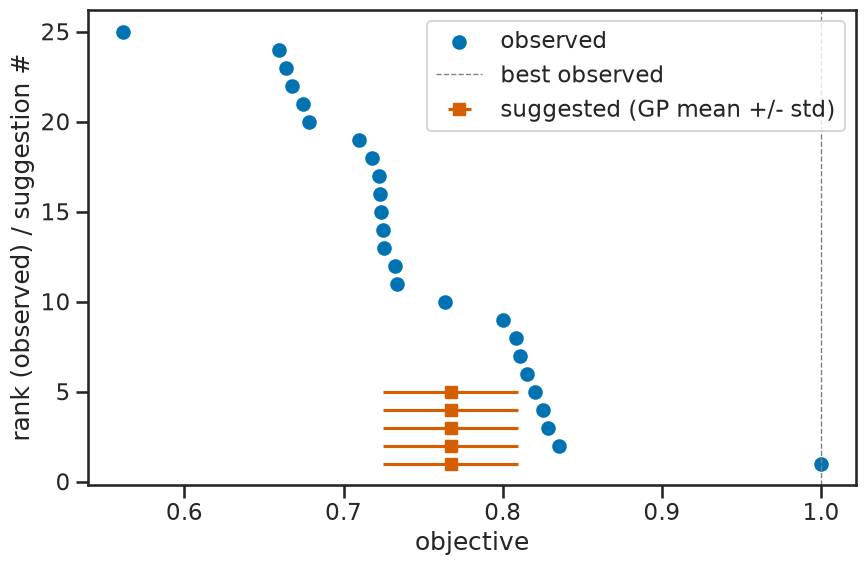

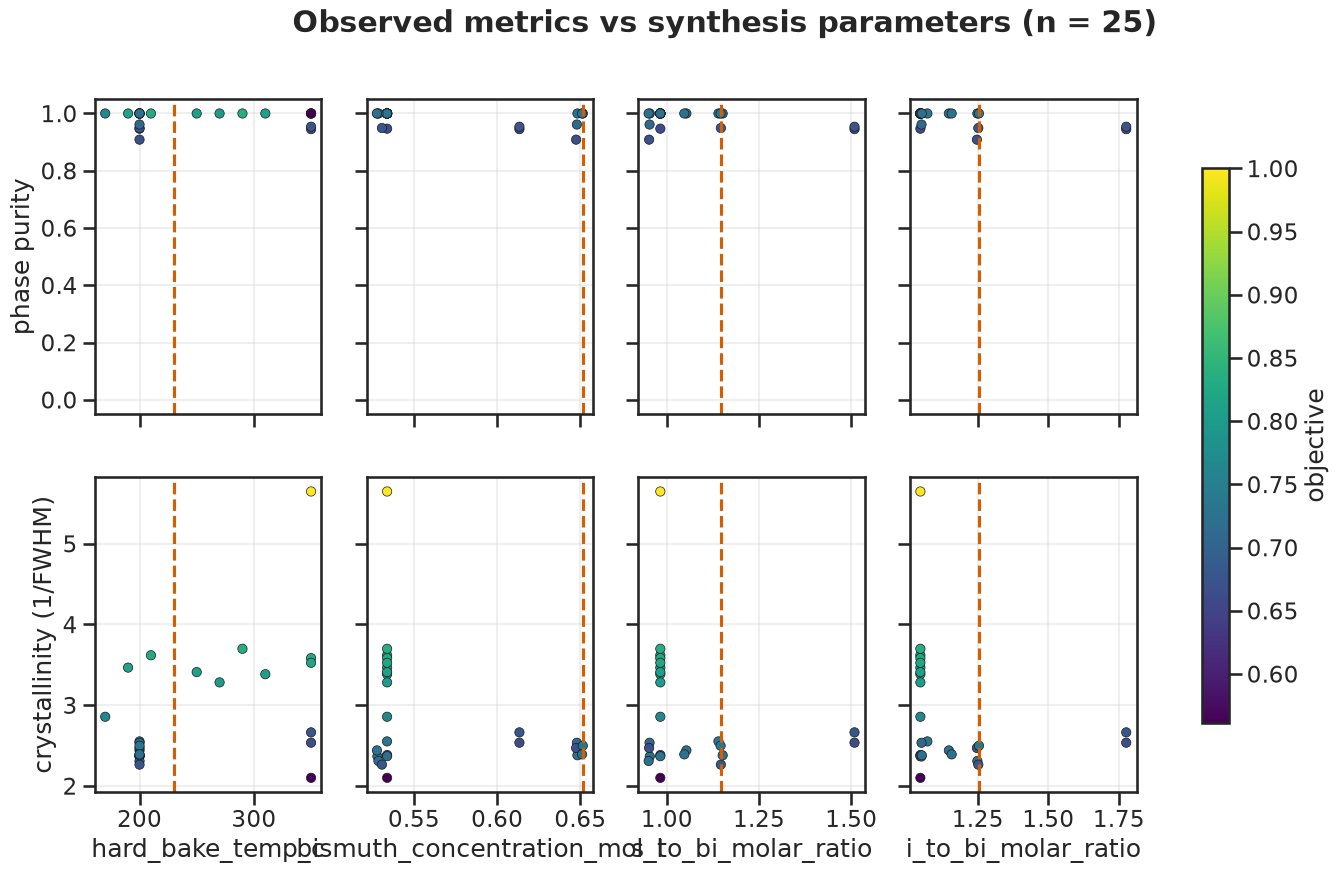

In [2]:
import matplotlib.pyplot as plt

from xrd_bo_optimization_tf.bayesian_opt import save_suggestions, suggest_next_conditions
from xrd_bo_optimization_tf.config import FIGURES_DIR, RESULTS_DATA_DIR
from xrd_bo_optimization_tf.plotting import plot_bo_suggestions, plot_parameter_metrics

suggestions = suggest_next_conditions(
    df_bo,
    n_suggestions=5,
    random_state=0,
    parameter_columns=BO_PARAMS,
)
suggestions_path = save_suggestions(
    suggestions,
    RESULTS_DATA_DIR / "bisi_bo_suggestions.csv",
)
print(suggestions.round(4).to_string(index=False))
print(f"Saved BiSI suggestions to {suggestions_path}")

objective_figure = plot_bo_suggestions(
    df_bo,
    suggestions,
    FIGURES_DIR / "bisi_bo_suggestions.png",
)
parameter_figure = plot_parameter_metrics(
    df_bo,
    suggestions,
    parameter_columns=BO_PARAMS,
    output_path=FIGURES_DIR / "bisi_bo_parameter_plots.png",
)
plt.show()